# Financial Transaction Fraud Detector
## Notebook 01 - Data Collection & Cleaning

**Owner:** Moaz Farag  
**Role:** Data Collection & Cleaning, project coordination  
**Course / University:** AI in Cybersecurity, Sohag University  
**Date:** 2026-11-24

**Goal.** Load the PaySim data efficiently, check its quality, decide what to keep, and save a clean copy plus a small sample for the app.

**Inputs:** `data/raw/PS_20174392719_1491204439457_log.csv (Kaggle ealaxi/paysim1)`

**Outputs:** `data/processed/clean.parquet`, `data/sample.csv`, `reports/figures/01_*.png`

Run the notebooks in order 01, 02, 03, 04a, 04b, 05; each one reads the files saved by the previous one.

## Setup
We add the project folder to Python's path so we can use the shared helpers in `src/`,
and we apply one chart style that all notebooks, slides and reports share.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, plotstyle

plotstyle.apply()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

## 1. Where the data comes from

We use **PaySim**, a public dataset on Kaggle (`ealaxi/paysim1`).

- PaySim is a **simulator** built by Lopez-Rojas, Elmir and Axelsson (EMSS 2016). It was calibrated on
  one month of real transaction logs from a mobile-money service in an African country.
- Because the data is **simulated**, it contains no real customers and no private information,
  which is why it is widely used for teaching and research on fraud detection.
- Each row is one transaction. `step` is one hour of simulated time (743 hours, about 31 days).

| Column | Meaning |
|---|---|
| step | hour of the simulation (1 to 743) |
| type | CASH_IN, CASH_OUT, DEBIT, PAYMENT, TRANSFER |
| amount | amount of money moved |
| nameOrig / nameDest | sender / receiver account ID (C = customer, M = merchant) |
| oldbalanceOrg / newbalanceOrig | sender balance before / after |
| oldbalanceDest / newbalanceDest | receiver balance before / after |
| isFraud | 1 if the transaction is fraud (our target) |
| isFlaggedFraud | 1 if the simulator's simple rule flagged it |

## 2. Loading the file efficiently

The CSV is about 470 MB with 6.36 million rows. We read it **once**, choosing compact column types:
`type` as a *category* (only 5 values), `step` as a small integer, and the flags as 1-byte integers.
Money columns stay as 64-bit floats so that cents are not lost (balance checks later need exact values).

In [2]:
import time

print("Reading:", data.RAW_CSV.name)
start = time.time()
raw = data.load_raw()
print(f"Loaded {len(raw):,} rows x {raw.shape[1]} columns in {time.time() - start:.1f} s")
print(f"Memory in pandas: {raw.memory_usage(deep=True).sum() / 1e9:.2f} GB")

Reading: PS_20174392719_1491204439457_log.csv


Loaded 6,362,620 rows x 11 columns in 5.9 s
Memory in pandas: 0.52 GB


In [3]:
raw.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.64",C1231006815,"170,136.00","160,296.36",M1979787155,0.00,0.00,0,0
1,1,PAYMENT,"1,864.28",C1666544295,"21,249.00","19,384.72",M2044282225,0.00,0.00,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.00,0.00,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,"21,182.00",0.00,1,0
4,1,PAYMENT,"11,668.14",C2048537720,"41,554.00","29,885.86",M1230701703,0.00,0.00,0,0


In [4]:
pd.DataFrame({"dtype": raw.dtypes.astype(str), "example": raw.iloc[0].astype(str)})

,dtype,example
step,int16,1
type,category,PAYMENT
amount,float64,9839.64
nameOrig,string,C1231006815
oldbalanceOrg,float64,170136.0
newbalanceOrig,float64,160296.36
nameDest,string,M1979787155
oldbalanceDest,float64,0.0
newbalanceDest,float64,0.0
isFraud,int8,0


## 3. Data quality checks

We check the usual problems: missing values, duplicated rows, impossible amounts, negative balances,
and unexpected category values.

In [5]:
checks = pd.DataFrame({
    "missing_values": raw.isna().sum(),
})
checks["missing_pct"] = 100 * checks["missing_values"] / len(raw)
checks

,missing_values,missing_pct
step,0,0.00
type,0,0.00
amount,0,0.00
nameOrig,0,0.00
oldbalanceOrg,0,0.00
newbalanceOrig,0,0.00
nameDest,0,0.00
oldbalanceDest,0,0.00
newbalanceDest,0,0.00
isFraud,0,0.00


In [6]:
n_dup = int(raw.duplicated().sum())
print(f"Fully duplicated rows: {n_dup:,}")

money = ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
neg = (raw[money] < 0).sum()
print("Negative values per money column:")
print(neg.to_string())

zero_amount = raw[raw["amount"] == 0]
print(f"\nRows with amount = 0: {len(zero_amount)}")
print(zero_amount.groupby(["type", "isFraud"], observed=True).size().rename("rows").to_string())

Fully duplicated rows: 0
Negative values per money column:
amount            0
oldbalanceOrg     0
newbalanceOrig    0
oldbalanceDest    0
newbalanceDest    0

Rows with amount = 0: 16
type      isFraud
CASH_OUT  1          16


In [7]:
print("Transaction types:", sorted(raw["type"].astype(str).unique()))
print(f"Step range: {raw['step'].min()} to {raw['step'].max()} ({raw['step'].nunique()} distinct hours)")

prefix = pd.DataFrame({
    "nameOrig": raw["nameOrig"].str[0].value_counts(),
    "nameDest": raw["nameDest"].str[0].value_counts(),
}).fillna(0).astype(int)
prefix.index.name = "ID prefix"
prefix

Transaction types: ['CASH_IN', 'CASH_OUT', 'DEBIT', 'PAYMENT', 'TRANSFER']
Step range: 1 to 743 (743 distinct hours)


,nameOrig,nameDest
ID prefix,,
C,6362620,4211125
M,0,2151495


## 4. Which transaction types contain fraud?

Before modeling we check where fraud actually happens. We do not assume it; we count it.

In [8]:
by_type = (raw.groupby("type", observed=True)["isFraud"]
           .agg(transactions="size", fraud="sum"))
by_type["fraud_rate_pct"] = 100 * by_type["fraud"] / by_type["transactions"]
by_type.sort_values("transactions", ascending=False)

,transactions,fraud,fraud_rate_pct
type,,,
CASH_OUT,2237500,4116,0.18
PAYMENT,2151495,0,0.00
CASH_IN,1399284,0,0.00
TRANSFER,532909,4097,0.77
DEBIT,41432,0,0.00


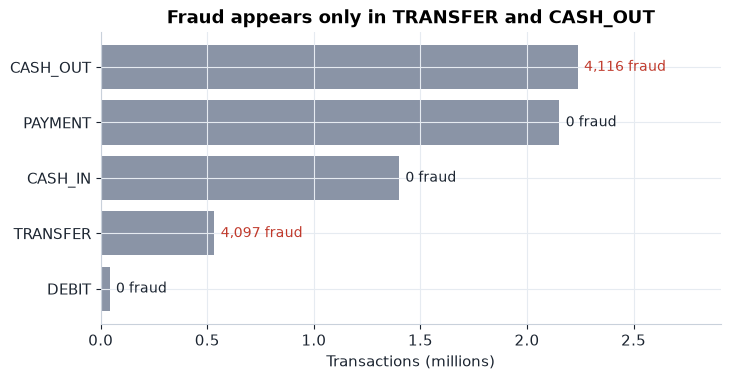

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
order = by_type.sort_values("transactions", ascending=True)
ax.barh(order.index.astype(str), order["transactions"] / 1e6, color=plotstyle.GREY, label="All transactions")
for i, (t, r) in enumerate(order.iterrows()):
    ax.text(r["transactions"] / 1e6 + 0.03, i, f"{int(r['fraud']):,} fraud", va="center",
            color=plotstyle.RED if r["fraud"] else plotstyle.INK, fontsize=10)
ax.set_xlabel("Transactions (millions)")
ax.set_title("Fraud appears only in TRANSFER and CASH_OUT")
ax.set_xlim(0, order["transactions"].max() / 1e6 * 1.3)
plotstyle.save(fig, "01_fraud_by_type")
plt.show()

**Why we model only TRANSFER and CASH_OUT.** All fraud cases are in these two types. In PaySim, a
fraudster takes over an account, **transfers** the money to another account, and then **cashes it out**.
A model trained on all types would spend effort learning that PAYMENT, DEBIT and CASH_IN are never
fraud, which is trivial. In the app, the other three types get the message
"Low risk: no fraud of this type was observed in the data".

We still keep **all types** in the clean file, because the receiver-history features in notebook 03
count every earlier incoming transaction of an account, whatever its type.

## 5. Cleaning decisions

1. **No missing values** and **no fully duplicated rows** were found, so nothing is dropped for those reasons.
2. **Zero-amount rows** are kept. They are rare and are all labeled fraud in the data, so dropping
   them would hide part of the fraud. The feature code handles a zero amount safely.
3. Account IDs are kept in the clean file (needed for receiver history) but are **never** given to the model.
4. We add `row_id` (the original row order) so every later step can trace a row back to the source file.

In [10]:
clean = raw.drop_duplicates().reset_index(drop=True)
clean.insert(0, "row_id", np.arange(len(clean), dtype="int32"))

data.PROCESSED.mkdir(parents=True, exist_ok=True)
clean.to_parquet(data.CLEAN_PARQUET, index=False)
size_mb = data.CLEAN_PARQUET.stat().st_size / 1e6
print(f"Saved {data.CLEAN_PARQUET.relative_to(ROOT)}: {len(clean):,} rows, {size_mb:.0f} MB")

Saved data\processed\clean.parquet: 6,362,620 rows, 299 MB


## 6. A small sample file for the app

The app's **Batch check** tab accepts a CSV in PaySim format. We save a small **stratified** sample
(all five types in their real proportions, plus a few hundred fraud rows so the demo shows alerts).
It is small enough to live in the repository (under 2 MB) and serves as the upload template.

In [11]:
rng_seed = 7
fraud_rows = clean[clean["isFraud"] == 1].sample(n=300, random_state=rng_seed)
normal_pool = clean[clean["isFraud"] == 0]
normal_rows = normal_pool.groupby("type", observed=True).sample(
    frac=11_700 / len(normal_pool), random_state=rng_seed)
sample = (pd.concat([fraud_rows, normal_rows])
          .sort_values(["step", "row_id"])[data.PAYSIM_COLUMNS])
sample.to_csv(data.SAMPLE_CSV, index=False, float_format="%.2f")

sample_mb = data.SAMPLE_CSV.stat().st_size / 1e6
print(f"Saved data/sample.csv: {len(sample):,} rows, {int(sample['isFraud'].sum())} fraud, {sample_mb:.2f} MB")
assert sample["type"].notna().all()
sample["type"].astype(str).value_counts().rename("rows").to_frame()

Saved data/sample.csv: 11,999 rows, 300 fraud, 0.97 MB


,rows
type,
CASH_OUT,4257
PAYMENT,3961
CASH_IN,2576
TRANSFER,1129
DEBIT,76


In [12]:
n_rows = len(clean)
fraud_total = int(clean["isFraud"].sum())
fraud_types = by_type[by_type["fraud"] > 0].index.astype(str).tolist()
data.write_findings("01_data_cleaning", [
    f"The PaySim file has {n_rows:,} transactions over {clean['step'].nunique()} simulated hours (about 31 days).",
    f"Data quality is high: no missing values, {n_dup} duplicated rows and no negative amounts or balances.",
    f"Only {fraud_total:,} rows are fraud ({100 * fraud_total / n_rows:.2f}% of all transactions).",
    f"Fraud appears only in {' and '.join(fraud_types)}; PAYMENT, DEBIT and CASH_IN have zero fraud, so we model only these two types.",
    f"{len(zero_amount)} zero-amount rows exist ({int(zero_amount['isFraud'].sum())} of them fraud); we keep them.",
    f"Saved clean.parquet ({size_mb:.0f} MB) and a {len(sample):,}-row sample.csv ({sample_mb:.2f} MB) for the app.",
])
print("Findings saved.")

Findings saved.


## Key findings

- The PaySim file has 6,362,620 transactions over 743 simulated hours (about 31 days).
- Data quality is high: no missing values, 0 duplicated rows and no negative amounts or balances.
- Only 8,213 rows are fraud (0.13% of all transactions).
- Fraud appears only in CASH_OUT and TRANSFER; PAYMENT, DEBIT and CASH_IN have zero fraud, so we model only these two types.
- 16 zero-amount rows exist (16 of them fraud); we keep them.
- Saved clean.parquet (299 MB) and a 11,999-row sample.csv (0.97 MB) for the app.